DATA-VIZ HACK-A-BIT (2026–2027)

Course: 24ADI204 – Data Science and Visualization
Project: Flight Data 2024 Analysis
Team Number: 10

WEEK 1 – DATASET SELECTION AND SETUP

Objective:
To select a real-world dataset, download it using KaggleHub,
and understand the basic use of Pandas and NumPy for data analysis.




In [ ]:
!pip -q install kagglehub pandas numpy matplotlib seaborn

import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
dataset_path = kagglehub.dataset_download(
    "hrishitpatil/flight-data-2024"
)

print("Dataset downloaded successfully!")
print("Dataset location:", dataset_path)

100%|██████████| 270M/270M [00:12<00:00, 23.3MB/s]

Extracting files...


Dataset downloaded successfully!
Dataset location: /root/.cache/kagglehub/datasets/hrishitpatil/flight-data-2024/versions/2


In [ ]:
csv_candidates = glob.glob(
    os.path.join(dataset_path, "**", "flight_data_2024.csv"),
    recursive=True
)

if not csv_candidates:
    raise FileNotFoundError("Dataset CSV file not found.")

file_path = csv_candidates[0]

print("Dataset file:", file_path)
print("File size (GB):",
      round(os.path.getsize(file_path) / (1024**3), 2))

Dataset file: /kaggle/input/flight-data-2024/flight_data_2024.csv
File size (GB): 1.22


In [ ]:
sample_df = pd.read_csv(file_path, nrows=5)

print("First five rows of the dataset:")
display(sample_df)

First five rows of the dataset:


,year,month,day_of_month,day_of_week,fl_date,op_unique_carrier,op_carrier_fl_num,origin,origin_city_name,origin_state_nm,...,diverted,crs_elapsed_time,actual_elapsed_time,air_time,distance,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay
0,2024,1,1,1,2024-01-01,9E,4814.0,JFK,"New York, NY",New York,...,0,136.0,122.0,84.0,509.0,0,0,0,0,0
1,2024,1,1,1,2024-01-01,9E,4815.0,MSP,"Minneapolis, MN",Minnesota,...,0,130.0,114.0,88.0,622.0,0,0,0,0,0
2,2024,1,1,1,2024-01-01,9E,4817.0,JFK,"New York, NY",New York,...,0,106.0,90.0,61.0,288.0,0,0,0,0,0
3,2024,1,1,1,2024-01-01,9E,4817.0,RIC,"Richmond, VA",Virginia,...,0,111.0,76.0,51.0,288.0,0,0,0,0,0
4,2024,1,1,1,2024-01-01,9E,4818.0,DTW,"Detroit, MI",Michigan,...,0,79.0,70.0,45.0,237.0,0,0,0,0,0


In [ ]:
print("Number of rows in sample:", sample_df.shape[0])
print("Number of columns:", sample_df.shape[1])

print("\nColumn names:")
print(sample_df.columns.tolist())

print("\nData types:")
print(sample_df.dtypes)

Number of rows in sample: 5
Number of columns: 35

Column names:
['year', 'month', 'day_of_month', 'day_of_week', 'fl_date', 'op_unique_carrier', 'op_carrier_fl_num', 'origin', 'origin_city_name', 'origin_state_nm', 'dest', 'dest_city_name', 'dest_state_nm', 'crs_dep_time', 'dep_time', 'dep_delay', 'taxi_out', 'wheels_off', 'wheels_on', 'taxi_in', 'crs_arr_time', 'arr_time', 'arr_delay', 'cancelled', 'cancellation_code', 'diverted', 'crs_elapsed_time', 'actual_elapsed_time', 'air_time', 'distance', 'carrier_delay', 'weather_delay', 'nas_delay', 'security_delay', 'late_aircraft_delay']

Data types:
year                     int64
month                    int64
day_of_month             int64
day_of_week              int64
fl_date                 object
op_unique_carrier       object
op_carrier_fl_num      float64
origin                  object
origin_city_name        object
origin_state_nm         object
dest                    object
dest_city_name          object
dest_state_nm          

In [ ]:
numbers = np.array([10, 20, 30, 40, 50])

print("NumPy Array:", numbers)
print("Mean:", np.mean(numbers))
print("Maximum:", np.max(numbers))
print("Minimum:", np.min(numbers))
print("Standard Deviation:", np.std(numbers))

NumPy Array: [10 20 30 40 50]
Mean: 30.0
Maximum: 50
Minimum: 10
Standard Deviation: 14.142135623730951


In [ ]:
print("PROJECT DATASET DETAILS")
print("-----------------------")
print("Dataset Name: Flight Data 2024")
print("Source: Kaggle")
print("Dataset ID: hrishitpatil/flight-data-2024")
print("File Name: flight_data_2024.csv")
print("Project Team: Team 10")
print("Course: 24ADI204 – Data Science and Visualization")

PROJECT DATASET DETAILS
-----------------------
Dataset Name: Flight Data 2024
Source: Kaggle
Dataset ID: hrishitpatil/flight-data-2024
File Name: flight_data_2024.csv
Project Team: Team 10
Course: 24ADI204 – Data Science and Visualization


WEEK 1 – CONCLUSION

During this week, we selected the Flight Data 2024 dataset
from Kaggle. We downloaded the dataset using KaggleHub and
examined a small sample of the available records.

We also practised basic operations using Pandas and NumPy.
The dataset contains flight-related information that will
be used to study departure delays, arrival delays and other
flight-related patterns in the upcoming weeks.

# WEEK 2 – KNOW YOUR DATA

## Objective

To load the complete Flight Data 2024 dataset and understand its structure, size, column names, data types and initial data quality. A First Impression Report is generated to summarize the dataset.


### Introduction

In this week, we explore the complete Flight Data 2024 dataset to understand the information it contains. We inspect the number of records, columns, data types, missing values and duplicate records. This initial inspection helps us understand the dataset before performing data cleaning and analysis.


In [1]:
!pip -q install pandas numpy matplotlib seaborn kagglehub

import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
dataset_path = kagglehub.dataset_download("hrishitpatil/flight-data-2024")

print("Dataset downloaded successfully!")
print("Dataset location:", dataset_path)

Using Colab cache for faster access to the 'flight-data-2024' dataset.
Dataset downloaded successfully!
Dataset location: /kaggle/input/flight-data-2024


In [3]:
csv_candidates = glob.glob(
    os.path.join(dataset_path, "**", "flight_data_2024.csv"),
    recursive=True
)

if not csv_candidates:
    raise FileNotFoundError("Dataset file not found!")

file_path = csv_candidates[0]

print("CSV File:", file_path)
print("File Size:", round(os.path.getsize(file_path)/(1024**3), 2), "GB")

CSV File: /kaggle/input/flight-data-2024/flight_data_2024.csv
File Size: 1.22 GB


In [4]:
df = pd.read_csv(file_path, low_memory=False)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

Dataset loaded successfully!
Dataset Shape: (7079081, 35)


In [5]:
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])
print("Total Records:", len(df))

Total Rows: 7079081
Total Columns: 35
Total Records: 7079081


In [6]:
print("Columns in the Dataset:\n")

for column in df.columns:
    print(column)

Columns in the Dataset:

year
month
day_of_month
day_of_week
fl_date
op_unique_carrier
op_carrier_fl_num
origin
origin_city_name
origin_state_nm
dest
dest_city_name
dest_state_nm
crs_dep_time
dep_time
dep_delay
taxi_out
wheels_off
wheels_on
taxi_in
crs_arr_time
arr_time
arr_delay
cancelled
cancellation_code
diverted
crs_elapsed_time
actual_elapsed_time
air_time
distance
carrier_delay
weather_delay
nas_delay
security_delay
late_aircraft_delay


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7079081 entries, 0 to 7079080
Data columns (total 35 columns):
 #   Column               Dtype  
---  ------               -----  
 0   year                 int64  
 1   month                int64  
 2   day_of_month         int64  
 3   day_of_week          int64  
 4   fl_date              object 
 5   op_unique_carrier    object 
 6   op_carrier_fl_num    float64
 7   origin               object 
 8   origin_city_name     object 
 9   origin_state_nm      object 
 10  dest                 object 
 11  dest_city_name       object 
 12  dest_state_nm        object 
 13  crs_dep_time         int64  
 14  dep_time             float64
 15  dep_delay            float64
 16  taxi_out             float64
 17  wheels_off           float64
 18  wheels_on            float64
 19  taxi_in              float64
 20  crs_arr_time         int64  
 21  arr_time             float64
 22  arr_delay            float64
 23  cancelled            int64  
 24

In [8]:
print("First Five Records:")
display(df.head())

First Five Records:


,year,month,day_of_month,day_of_week,fl_date,op_unique_carrier,op_carrier_fl_num,origin,origin_city_name,origin_state_nm,...,diverted,crs_elapsed_time,actual_elapsed_time,air_time,distance,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay
0,2024,1,1,1,2024-01-01,9E,4814.0,JFK,"New York, NY",New York,...,0,136.0,122.0,84.0,509.0,0,0,0,0,0
1,2024,1,1,1,2024-01-01,9E,4815.0,MSP,"Minneapolis, MN",Minnesota,...,0,130.0,114.0,88.0,622.0,0,0,0,0,0
2,2024,1,1,1,2024-01-01,9E,4817.0,JFK,"New York, NY",New York,...,0,106.0,90.0,61.0,288.0,0,0,0,0,0
3,2024,1,1,1,2024-01-01,9E,4817.0,RIC,"Richmond, VA",Virginia,...,0,111.0,76.0,51.0,288.0,0,0,0,0,0
4,2024,1,1,1,2024-01-01,9E,4818.0,DTW,"Detroit, MI",Michigan,...,0,79.0,70.0,45.0,237.0,0,0,0,0,0


In [9]:
print("Last Five Records:")
display(df.tail())

Last Five Records:


,year,month,day_of_month,day_of_week,fl_date,op_unique_carrier,op_carrier_fl_num,origin,origin_city_name,origin_state_nm,...,diverted,crs_elapsed_time,actual_elapsed_time,air_time,distance,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay
7079076,2024,12,31,2,2024-12-31,YX,5857.0,MYR,"Myrtle Beach, SC",South Carolina,...,0,117.0,102.0,76.0,563.0,0,0,0,0,0
7079077,2024,12,31,2,2024-12-31,YX,5859.0,JFK,"New York, NY",New York,...,0,89.0,72.0,51.0,273.0,0,0,0,0,0
7079078,2024,12,31,2,2024-12-31,YX,5859.0,PWM,"Portland, ME",Maine,...,0,89.0,83.0,50.0,273.0,0,0,0,0,0
7079079,2024,12,31,2,2024-12-31,YX,5862.0,JFK,"New York, NY",New York,...,0,89.0,81.0,42.0,209.0,0,0,0,0,0
7079080,2024,12,31,2,2024-12-31,YX,5863.0,SYR,"Syracuse, NY",New York,...,0,83.0,72.0,47.0,209.0,0,0,0,0,0


In [10]:
print("Random Five Records:")
display(df.sample(5, random_state=42))

Random Five Records:


,year,month,day_of_month,day_of_week,fl_date,op_unique_carrier,op_carrier_fl_num,origin,origin_city_name,origin_state_nm,...,diverted,crs_elapsed_time,actual_elapsed_time,air_time,distance,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay
1996999,2024,4,18,4,2024-04-18,MQ,3535.0,DFW,"Dallas/Fort Worth, TX",Texas,...,0,151.0,144.0,119.0,835.0,0,0,0,0,0
848,2024,1,1,1,2024-01-01,AA,148.0,CLT,"Charlotte, NC",North Carolina,...,0,286.0,273.0,253.0,1773.0,0,0,0,0,0
6697762,2024,12,12,4,2024-12-12,9E,5440.0,CHA,"Chattanooga, TN",Tennessee,...,0,59.0,50.0,29.0,106.0,0,0,0,0,0
1810495,2024,4,8,1,2024-04-08,WN,1971.0,OMA,"Omaha, NE",Nebraska,...,0,180.0,177.0,163.0,1099.0,0,0,0,0,0
828505,2024,2,16,5,2024-02-16,WN,862.0,BWI,"Baltimore, MD",Maryland,...,0,90.0,96.0,76.0,399.0,0,0,0,0,0


In [11]:
print("Statistical Summary of Dataset:")
display(df.describe(include="all").T)

Statistical Summary of Dataset:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
year,7079081.0,NaN,NaN,NaN,2024.0,0.0,2024.0,2024.0,2024.0,2024.0,2024.0
month,7079081.0,NaN,NaN,NaN,6.584868,3.396806,1.0,4.0,7.0,10.0,12.0
day_of_month,7079081.0,NaN,NaN,NaN,15.784451,8.786433,1.0,8.0,16.0,23.0,31.0
day_of_week,7079081.0,NaN,NaN,NaN,3.981945,2.012279,1.0,2.0,4.0,6.0,7.0
fl_date,7079081,366,2024-12-01,21764,NaN,NaN,NaN,NaN,NaN,NaN,NaN
op_unique_carrier,7079081,15,WN,1419419,NaN,NaN,NaN,NaN,NaN,NaN,NaN
op_carrier_fl_num,7079080.0,NaN,NaN,NaN,2504.622501,1652.252505,1.0,1151.0,2227.0,3717.0,8819.0
origin,7079081,348,ATL,341910,NaN,NaN,NaN,NaN,NaN,NaN,NaN
origin_city_name,7079081,342,"Chicago, IL",359685,NaN,NaN,NaN,NaN,NaN,NaN,NaN
origin_state_nm,7079081,52,Texas,751839,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [12]:
print("Data Types of Each Column:")
display(df.dtypes)

Data Types of Each Column:


,0
year,int64
month,int64
day_of_month,int64
day_of_week,int64
fl_date,object
op_unique_carrier,object
op_carrier_fl_num,float64
origin,object
origin_city_name,object
origin_state_nm,object


In [13]:
print("Count of Each Data Type:")
display(df.dtypes.value_counts())

Count of Each Data Type:


,count
int64,13
float64,13
object,9


In [14]:
missing_values = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

missing_values = missing_values[
    missing_values["Missing Count"] > 0
].sort_values(
    by="Missing Percentage",
    ascending=False
)

print("Missing Value Summary:")
display(missing_values)

Missing Value Summary:


,Missing Count,Missing Percentage
cancellation_code,6982766,98.64
air_time,113814,1.61
actual_elapsed_time,113814,1.61
arr_delay,113814,1.61
arr_time,97854,1.38
wheels_on,97856,1.38
taxi_in,97856,1.38
wheels_off,95734,1.35
taxi_out,95734,1.35
dep_delay,92970,1.31


In [15]:
duplicate_count = df.duplicated().sum()

print("Total Duplicate Records:", duplicate_count)

Total Duplicate Records: 0


In [16]:
important_columns = [
    "dep_delay",
    "arr_delay",
    "origin",
    "dest",
    "op_unique_carrier",
    "distance",
    "cancelled",
    "diverted"
]

print("Important Project Columns:")
display(df[important_columns].head())

Important Project Columns:


,dep_delay,arr_delay,origin,dest,op_unique_carrier,distance,cancelled,diverted
0,-5.0,-19.0,JFK,DTW,9E,509.0,0,0
1,-14.0,-30.0,MSP,CLE,9E,622.0,0,0
2,-4.0,-20.0,JFK,RIC,9E,288.0,0,0
3,-7.0,-42.0,RIC,JFK,9E,288.0,0,0
4,-5.0,-14.0,DTW,MKE,9E,237.0,0,0


In [17]:
first_impression = pd.DataFrame({
    "Category": [
        "Total Rows",
        "Total Columns",
        "Total Missing Values",
        "Duplicate Records",
        "Numerical Columns",
        "Categorical Columns"
    ],
    "Value": [
        df.shape[0],
        df.shape[1],
        df.isnull().sum().sum(),
        df.duplicated().sum(),
        df.select_dtypes(include=np.number).shape[1],
        df.select_dtypes(include="object").shape[1]
    ]
})

print("FIRST IMPRESSION REPORT")
display(first_impression)

FIRST IMPRESSION REPORT


,Category,Value
0,Total Rows,7079081
1,Total Columns,35
2,Total Missing Values,7994873
3,Duplicate Records,0
4,Numerical Columns,26
5,Categorical Columns,9


In [18]:
first_impression.to_csv(
    "/content/flight_data_first_impression.csv",
    index=False
)

print("First Impression Report saved successfully!")

First Impression Report saved successfully!


## Conclusion

In Week 2, the complete Flight Data 2024 dataset was loaded and inspected. Its structure, dimensions, column names and data types were examined. Missing values and duplicate records were also identified. A First Impression Report was generated to summarize the initial condition of the dataset.

This inspection provides a better understanding of the dataset and prepares it for the data cleaning process in the next week.


# WEEK 3 – THE CLEANING SPRINT

## Objective

To identify and handle missing values, check duplicate records, detect invalid values and identify outliers in the Flight Data 2024 dataset using the IQR method, Boxplots and Z-score.


## Introduction

Data cleaning is an important step in data analysis because real-world datasets may contain missing values, duplicate records, invalid entries and outliers.

In this week, we examine the quality of the Flight Data 2024 dataset and apply suitable strategies to handle data quality issues. We also use statistical methods and visualizations to identify outliers without unnecessarily removing genuine flight records.


In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import glob
import warnings

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [20]:
dataset_path = kagglehub.dataset_download(
    "hrishitpatil/flight-data-2024"
)

csv_candidates = glob.glob(
    os.path.join(dataset_path, "**", "flight_data_2024.csv"),
    recursive=True
)

file_path = csv_candidates[0]

df = pd.read_csv(file_path, low_memory=False)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

Using Colab cache for faster access to the 'flight-data-2024' dataset.
Dataset loaded successfully!
Dataset Shape: (7079081, 35)


## 1. Missing Value Analysis

Missing values occur when information is not recorded in a dataset. Identifying them helps us understand the completeness of the data and decide how to handle them appropriately.


In [21]:
missing_report = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().mean() * 100
    ).round(2)
})

missing_report = missing_report[
    missing_report["Missing Count"] > 0
].sort_values(
    by="Missing Percentage",
    ascending=False
)

print("Missing Value Report:")
display(missing_report)

Missing Value Report:


,Missing Count,Missing Percentage
cancellation_code,6982766,98.64
air_time,113814,1.61
actual_elapsed_time,113814,1.61
arr_delay,113814,1.61
arr_time,97854,1.38
wheels_on,97856,1.38
taxi_in,97856,1.38
wheels_off,95734,1.35
taxi_out,95734,1.35
dep_delay,92970,1.31


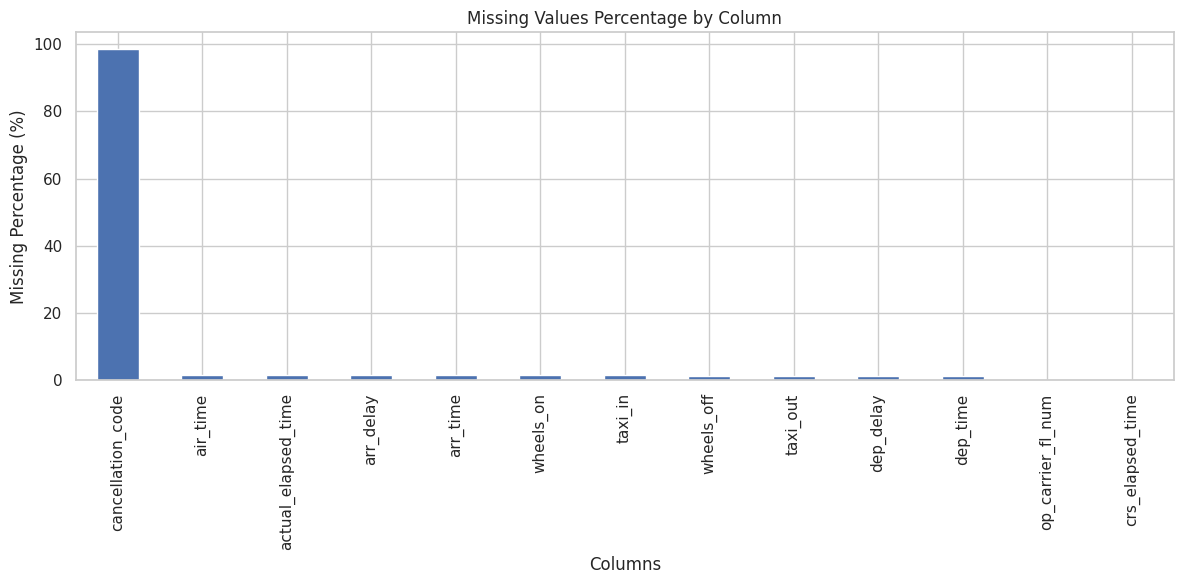

In [22]:
plt.figure(figsize=(12, 6))

missing_report["Missing Percentage"].plot(
    kind="bar"
)

plt.title("Missing Values Percentage by Column")
plt.xlabel("Columns")
plt.ylabel("Missing Percentage (%)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [23]:
print("Cancelled Flight Counts:")
display(df["cancelled"].value_counts())

print("Diverted Flight Counts:")
display(df["diverted"].value_counts())

Cancelled Flight Counts:


,count
cancelled,
0,6982766
1,96315


Diverted Flight Counts:


,count
diverted,
0,7061582
1,17499


In [24]:
columns_to_check = [
    "dep_time",
    "dep_delay",
    "taxi_out",
    "wheels_off",
    "wheels_on",
    "taxi_in",
    "arr_time",
    "arr_delay",
    "actual_elapsed_time",
    "air_time"
]

missing_by_cancellation = df.groupby(
    "cancelled"
)[columns_to_check].apply(
    lambda x: x.isnull().sum()
)

print("Missing Values by Cancellation Status:")
display(missing_by_cancellation)

Missing Values by Cancellation Status:


,dep_time,dep_delay,taxi_out,wheels_off,wheels_on,taxi_in,arr_time,arr_delay,actual_elapsed_time,air_time
cancelled,,,,,,,,,,
0,0,0,0,0,1541,1541,1539,17499,17499,17499
1,92659,92970,95734,95734,96315,96315,96315,96315,96315,96315


### Missing Value Treatment Strategy

Not all missing values should be replaced with the mean or median.

In this dataset, some flight details are missing because flights were cancelled or diverted. Replacing these values with artificial numbers could affect the accuracy of the analysis.

Therefore:

* Missing cancellation codes are replaced with "Not Cancelled" when the flight was not cancelled.
* Missing departure and arrival information is retained when the actual information is unavailable.
* Median imputation will be applied within the later machine-learning preprocessing pipeline, using the training data.


In [36]:
df.loc[
    df["cancelled"] == 0,
    "cancellation_code"
] = df.loc[
    df["cancelled"] == 0,
    "cancellation_code"
].fillna("Not Cancelled")

print(
    "Missing cancellation codes after treatment:",
    df["cancellation_code"].isnull().sum()
)

Missing cancellation codes after treatment: 0


## 2. Duplicate and Invalid Value Analysis

Duplicate records can affect the accuracy of analysis. Invalid values, such as negative flight distances or negative travel durations, must also be checked before further processing.


In [26]:
duplicate_count = df.duplicated().sum()

print("Total Duplicate Records:", duplicate_count)

Total Duplicate Records: 0


In [27]:
numeric_check_columns = [
    "crs_elapsed_time",
    "distance",
    "taxi_out",
    "taxi_in",
    "air_time"
]

invalid_counts = {}

for column in numeric_check_columns:
    invalid_counts[column] = (
        df[column] < 0
    ).sum()

invalid_report = pd.DataFrame(
    list(invalid_counts.items()),
    columns=["Column", "Negative Value Count"]
)

display(invalid_report)

,Column,Negative Value Count
0,crs_elapsed_time,1
1,distance,0
2,taxi_out,0
3,taxi_in,0
4,air_time,0


In [28]:
invalid_crs = (
    df["crs_elapsed_time"] < 0
).sum()

print("Invalid CRS Elapsed Time Before:",
      invalid_crs)

df.loc[
    df["crs_elapsed_time"] < 0,
    "crs_elapsed_time"
] = np.nan

print("Invalid CRS Elapsed Time After:",
      (df["crs_elapsed_time"] < 0).sum())

Invalid CRS Elapsed Time Before: 1
Invalid CRS Elapsed Time After: 0


## 3. Outlier Detection Using IQR Method

Outliers are values that differ significantly from the majority of observations.

The Interquartile Range (IQR) method identifies outliers using the first quartile (Q1), third quartile (Q3) and interquartile range.

IQR = Q3 − Q1

Lower Bound = Q1 − 1.5 × IQR

Upper Bound = Q3 + 1.5 × IQR


In [29]:
iqr_columns = [
    "dep_delay",
    "arr_delay",
    "taxi_out",
    "taxi_in",
    "crs_elapsed_time",
    "actual_elapsed_time",
    "air_time",
    "distance"
]

iqr_results = []

for column in iqr_columns:

    data = df[column].dropna()

    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = (
        (data < lower_bound) |
        (data > upper_bound)
    ).sum()

    percentage = (outliers / len(data)) * 100

    iqr_results.append([
        column,
        Q1,
        Q3,
        IQR,
        lower_bound,
        upper_bound,
        outliers,
        round(percentage, 2)
    ])

iqr_report = pd.DataFrame(
    iqr_results,
    columns=[
        "Column",
        "Q1",
        "Q3",
        "IQR",
        "Lower Bound",
        "Upper Bound",
        "Outlier Count",
        "Outlier Percentage"
    ]
)

display(iqr_report)

,Column,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,dep_delay,-6.0,9.0,15.0,-28.5,31.5,909066,13.01
1,arr_delay,-15.0,9.0,24.0,-51.0,45.0,670540,9.63
2,taxi_out,12.0,21.0,9.0,-1.5,34.5,355622,5.09
3,taxi_in,5.0,10.0,5.0,-2.5,17.5,466184,6.68
4,crs_elapsed_time,93.0,177.0,84.0,-33.0,303.0,360025,5.09
5,actual_elapsed_time,88.0,172.0,84.0,-38.0,298.0,341997,4.91
6,air_time,63.0,145.0,82.0,-60.0,268.0,349654,5.02
7,distance,399.0,1069.0,670.0,-606.0,2074.0,420064,5.93


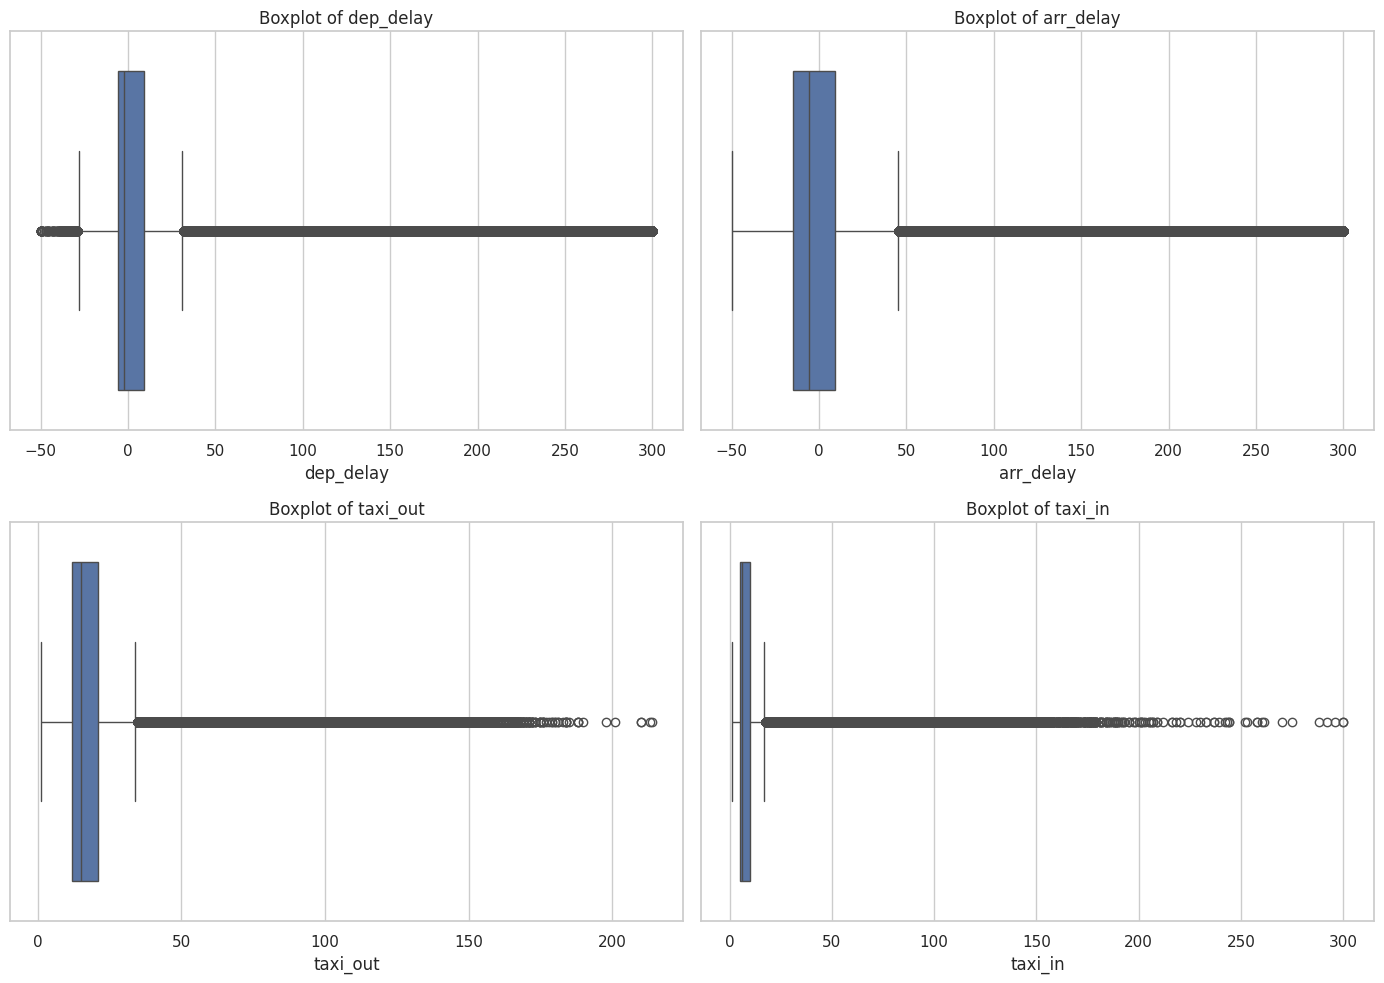

In [30]:
boxplot_columns = [
    "dep_delay",
    "arr_delay",
    "taxi_out",
    "taxi_in"
]

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 10)
)

for column, ax in zip(
    boxplot_columns,
    axes.flatten()
):

    sns.boxplot(
        x=df[column].dropna().clip(-50, 300),
        ax=ax
    )

    ax.set_title(
        "Boxplot of " + column
    )

plt.tight_layout()
plt.show()

## 4. Outlier Detection Using Z-Score

Z-score measures how far a data value is from the mean in terms of standard deviations.

Formula:

Z = (X − Mean) / Standard Deviation

Values with an absolute Z-score greater than 3 are considered potential outliers in this analysis.


In [31]:
zscore_columns = [
    "dep_delay",
    "arr_delay",
    "taxi_out",
    "taxi_in",
    "crs_elapsed_time",
    "actual_elapsed_time",
    "air_time",
    "distance"
]

zscore_results = []

for column in zscore_columns:

    data = df[column].dropna()

    mean = data.mean()
    std = data.std()

    z_scores = ((data - mean) / std).abs()

    outlier_count = (z_scores > 3).sum()

    zscore_results.append([
        column,
        mean,
        std,
        outlier_count
    ])

zscore_report = pd.DataFrame(
    zscore_results,
    columns=[
        "Column",
        "Mean",
        "Standard Deviation",
        "Z-Score Outlier Count"
    ]
)

display(zscore_report)

,Column,Mean,Standard Deviation,Z-Score Outlier Count
0,dep_delay,12.677082,56.059970,100953
1,arr_delay,7.098245,57.991271,98400
2,taxi_out,17.904450,9.677410,124843
3,taxi_in,8.326030,6.844510,129604
4,crs_elapsed_time,146.766512,72.386837,100264
5,actual_elapsed_time,141.215140,72.307811,91593
6,air_time,114.999716,70.369553,91933
7,distance,833.906150,596.253594,61230


In [32]:
comparison = iqr_report[
    ["Column", "Outlier Count"]
].merge(
    zscore_report[
        ["Column", "Z-Score Outlier Count"]
    ],
    on="Column"
)

print("IQR and Z-Score Outlier Comparison:")
display(comparison)

IQR and Z-Score Outlier Comparison:


,Column,Outlier Count,Z-Score Outlier Count
0,dep_delay,909066,100953
1,arr_delay,670540,98400
2,taxi_out,355622,124843
3,taxi_in,466184,129604
4,crs_elapsed_time,360025,100264
5,actual_elapsed_time,341997,91593
6,air_time,349654,91933
7,distance,420064,61230


## 5. Automated Data Quality Report

An automated data quality report is generated to summarize the condition of the dataset after the initial cleaning operations. It includes data types, missing values and unique values for each column.


In [33]:
quality_report = pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Missing Count": df.isnull().sum().values,
    "Missing Percentage": (
        df.isnull().mean().values * 100
    ).round(2),
    "Unique Values": df.nunique(
        dropna=True
    ).values
})

display(quality_report)

,Column,Data Type,Missing Count,Missing Percentage,Unique Values
0,year,int64,0,0.00,1
1,month,int64,0,0.00,12
2,day_of_month,int64,0,0.00,31
3,day_of_week,int64,0,0.00,7
4,fl_date,object,0,0.00,366
5,op_unique_carrier,object,0,0.00,15
6,op_carrier_fl_num,float64,1,0.00,6862
7,origin,object,0,0.00,348
8,origin_city_name,object,0,0.00,342
9,origin_state_nm,object,0,0.00,52


In [34]:
quality_report.to_csv(
    "/content/data_quality_report_week3.csv",
    index=False
)

iqr_report.to_csv(
    "/content/iqr_outlier_report.csv",
    index=False
)

zscore_report.to_csv(
    "/content/zscore_outlier_report.csv",
    index=False
)

print("All Week 3 reports saved successfully!")

All Week 3 reports saved successfully!


In [35]:
print("WEEK 3 – FINAL DATA CLEANING SUMMARY")

print("-----------------------------------")

print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

print("Duplicate Records:", df.duplicated().sum())

print(
    "Missing Values:",
    df.isnull().sum().sum()
)

print(
    "Negative CRS Elapsed Time:",
    (df["crs_elapsed_time"] < 0).sum()
)

print("-----------------------------------")
print("Week 3 cleaning checks completed!")

WEEK 3 – FINAL DATA CLEANING SUMMARY
-----------------------------------
Total Rows: 7079081
Total Columns: 35
Duplicate Records: 0
Missing Values: 1012108
Negative CRS Elapsed Time: 0
-----------------------------------
Week 3 cleaning checks completed!


## Conclusion

In Week 3, the Flight Data 2024 dataset was examined for missing values, duplicate records and invalid entries. A suitable strategy was followed to handle missing cancellation codes while retaining unavailable flight information that could have a meaningful reason.

Outliers were identified using the IQR method, Boxplots and Z-score. An automated Data Quality Report was also generated.

These steps helped us understand the quality of the dataset and prepare it for further exploratory data analysis.
